In [1]:
%load_ext autoreload
%autoreload 2

In [15]:
import pandas as pd
import xarray as xr

from fast_o3_iv import utils, metrics
import fast_o3_iv.bias_correction as bc
from fast_o3_iv.config import INTERIM_DATA_DIR
from fast_o3_iv.modeling.train import DatasetConfig


In [3]:
# load observation osdma8
ramp_osdma8 = xr.open_dataset((
        INTERIM_DATA_DIR
        / "RAMP"
        / "Jacob_wRAMP_OSDMA8_1990_2017.nc"))


In [7]:
# load modeled monthly mda8o3
config_hist = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'historical',
            variable_setname = 'setC',
            year_range = range(1975,2015)
        )


In [55]:
wa6_hist = utils.load_or_aggregate_results(
    "inference",
    config_hist,
     "GPR-local",
)

Loading existing dataset from /home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/aggregated_results/NCAR/CESM2-WACCM6/historical/inference/setC/GPR-local/NCAR.CESM2-WACCM6.historical.inference.setC.GPR-local.nc


In [41]:
config_ssp245 = DatasetConfig(
            source_id = 'CESM2-WACCM6',
            cmip_experiment_id = 'ssp245',
            variable_setname = 'setC',
            year_range = range(2015,2055)
        )
wa6_ssp245 = utils.load_or_create_results_ds(
    "inference",
    config_ssp245,
     "GPR-local",
)

Loading existing dataset from /home/eleroy/proj-dirs/fast-o3-iv/data/processed/model_outputs/processed_results/NCAR/CESM2-WACCM6/ssp245/inference/setC/GPR-local/NCAR.CESM2-WACCM6.ssp245.inference.setC.GPR-local.nc


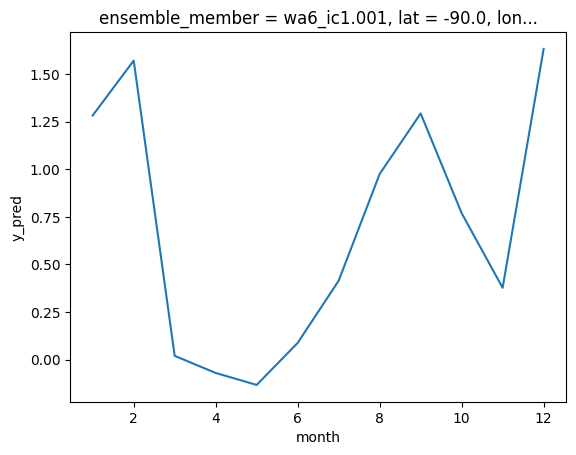

In [ ]:
# check that seasonal cycle is removed from original anomalies
wa6_hist['y_pred'].isel(ensemble_member=0, lat=0, lon=0).groupby('time.month').mean().plot()

In [ ]:
# add climatology (only required if target == mda8o3_anm (setC))
wa6_hist_2 = utils.add_mda8o3_climatology(wa6_hist, config_hist) 
wa6_ssp245_2 = utils.add_mda8o3_climatology(wa6_ssp245, config_ssp245) 


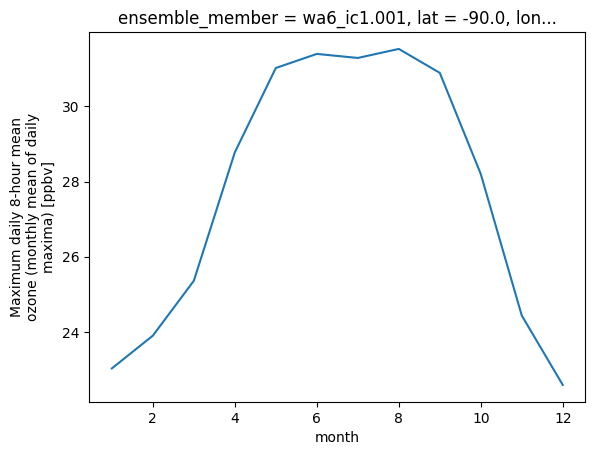

In [ ]:
# check that seasonal cycle is fixed
wa6_hist_2['y_pred'].isel(ensemble_member=0, lat=0, lon=0).groupby('time.month').mean().plot()

In [50]:
#convert monthly mda8o3 to osdma8 
wa6_hist_osdma8 = metrics.calc_osdma8(wa6_hist_2)
wa6_ssp245_osdma8 = metrics.calc_osdma8(wa6_ssp245_2)

In [51]:
# calculate scaling factor based on historical mod vs obs osdma8
scaling_factor, obs_base, mod_base = bc.get_bc_scaling_factor(wa6_hist_osdma8, ramp_osdma8)

In [52]:
# apply bias correction
wa6_hist_osdma8_bc = bc.bias_correct(wa6_hist_osdma8, scaling_factor)
wa6_ssp245_osdma8_bc = bc.bias_correct(wa6_ssp245_osdma8, scaling_factor)

In [ ]:
# save to netcdf
file_path = bc.return_osdma8_bc_path("inference", config_hist, "GPR-local")
wa6_hist_osdma8_bc.to_netcdf(file_path)

file_path = bc.return_osdma8_bc_path("inference", config_ssp245, "GPR-local")
wa6_ssp245_osdma8_bc.to_netcdf(file_path)